# Sufficiency ablation — qualitative generations

Applies the **sufficiency** intervention (spare the goal heads; blind every *other* head in layers
`>= FROM_LAYER` from the frontier's spec span) and greedy-decodes the frontier value, for each condition
in `SPECS`. Conditions are built with the same `build_condition` as `01_temporal_persistance.ipynb` §2
(frontier-prefilled up to `{var} =`).

For each condition it shows three generations:
- **baseline** — no ablation,
- **spare GOAL heads** — only the goal heads keep access to the task span (the sufficiency test),
- **spare RANDOM heads** — a matched control sparing an equal number of later-half non-goal heads.

If the goal-spared run still implements the frontier while the random-spared control fails, the goal
heads are *sufficient* to route the sub-goal. Reuses `scripts/evaluation/ablation_common.py`.

In [1]:
# bootstrap: pin a GPU (before torch), cd to repo root + path
import os, sys
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "6,7")   # 32B ~63GB; set to a free GPU
os.environ["TOKENIZERS_PARALLELISM"] = "false"
_d = os.getcwd()
while _d != '/' and not os.path.isdir(os.path.join(_d, 'src')):
    _d = os.path.dirname(_d)
sys.path.insert(0, _d); os.chdir(_d)

import random
import torch
from rich import print as rich_print
from rich.panel import Panel
from rich.table import Table
from rich.text import Text
from rich.markup import escape
from rich.box import SIMPLE_HEAVY

import src.diff.data as DATA
from src.models import ModelandTokenizer
from src.tokens import prepare_input
from src.goals import temporal_persistence as TP
from scripts.evaluation.ablation_common import (
    complement_heads, frontier_block_positions, generate_blocking_span_cached, judge_implements,
)

In [2]:
# load model (eager attention is required for the softmax-knockout hook)
MODEL_KEY = "Qwen/Qwen2.5-Coder-32B-Instruct"
SLUG = MODEL_KEY.split("/")[-1]
mt = ModelandTokenizer(model_key=MODEL_KEY, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
print(mt.n_layer, "layers ·", mt.n_heads, "heads")

Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

64 layers · 40 heads


In [3]:
# ── knobs ────────────────────────────────────────────────────────────────────────────
# Each SPEC is (datatype, target_pred, spec_ids). spec_ids[0] is the prefilled seed `a` (NOT probed);
# the target must be a non-seed entry (any middle/last slot). Valid ids per datatype:
#   [p.id for p in DATA.QTASKS[<datatype>].predicates]
SPECS = [
    # ("list[int]", "value_range",    ("has_duplicate", "value_range", "is_sorted")),
    # ("list[int]", "is_sorted",    ("count_even", "is_sorted", "value_range")),
    # ("list[str]", "has_palindrome", ("total_length", "has_palindrome", "count_capitalized")),
    ("list[str]", "total_vowels", ("count_capitalized", "total_vowels", "count_all_lowercase")),
    # ("list[str]", "all_unique_lengths", ("longest_word_length", "all_unique_lengths", "count_capitalized")),
]

LANG        = "python"        # "python" | "cpp"  (applied to all SPECS)
HEAD_BUDGET = 250             # goal-head set to spare (122 | 250)
FROM_LAYER  = 20              # blind non-goal heads in layers >= this (layers below untouched)
GEN_MAX_NEW = 64              # greedy budget for the frontier value
SHOW_CONTROL = True           # also run the random-spare control
CONTROL_SEED = 0
GRADE = True                  # oracle-grade each generation (does it implement the frontier?)

FORCE_RECOMPUTE = False       # ignore the on-disk cache and re-run the (expensive) generations

goal_heads = TP.load_goal_heads(mt, SLUG, HEAD_BUDGET)
print(f"{len(goal_heads)} goal heads (budget={HEAD_BUDGET}) · {len(SPECS)} conditions")

250 goal heads (budget=250) · 1 conditions


In [4]:
# ── helpers: build condition, generate (cached), and show ─────────────────────────────
import os, json, hashlib
CACHE_DIR = os.path.join("results", "notebook_caches", "sufficiency_qual", SLUG)
os.makedirs(CACHE_DIR, exist_ok=True)
CACHE_VER = "v1"

def _cache_path(datatype, target_pred, spec_ids):
    key = (f"{SLUG}|{datatype}|{target_pred}|{','.join(spec_ids)}|{LANG}|{HEAD_BUDGET}"
           f"|{FROM_LAYER}|{GEN_MAX_NEW}|{CONTROL_SEED}|grade={GRADE}|{CACHE_VER}")
    return os.path.join(CACHE_DIR, hashlib.md5(key.encode()).hexdigest()[:16] + ".json")

def build_condition(datatype, spec_ids, lang, other_id=None):
    """MultiPredicateInstance whose listed spec is exactly `spec_ids`: spec_ids[0] is the prefilled seed
    `a` (not probed); spec_ids[1:] are probed b, c, …. dst_frontier is a throwaway."""
    bank = {p.id: p for p in DATA.QTASKS[datatype].predicates}
    shared = tuple(bank[i] for i in spec_ids[:-1])
    if other_id is None:
        other_id = next(pid for pid in bank if pid not in spec_ids)
    return DATA.MultiPredicateInstance(
        datatype=datatype, shared=shared, src_frontier=bank[spec_ids[-1]], dst_frontier=bank[other_id],
        var_name=DATA.QTASKS[datatype].var_names[0], presentation="listed",
        src_lang=lang, dst_lang=lang, naming="letters", letter_stub="indent",
        meta={"datatype": datatype, "dst_next": other_id, "n_conditions": len(shared) + 1})

def _generate_spec(datatype, target_pred, spec_ids):
    """Compute the three generations (+ oracle verdicts) for one spec. Needs the model."""
    spec_ids = list(spec_ids)
    bank = {p.id: p for p in DATA.QTASKS[datatype].predicates}
    assert all(i in bank for i in spec_ids), f"[{datatype}] unknown id in {spec_ids}; valid: {sorted(bank)}"
    assert target_pred in spec_ids[1:], f"[{datatype}] target {target_pred!r} must be a non-seed entry of {spec_ids}"
    inst  = build_condition(datatype, spec_ids, LANG)
    preds = inst._preds_for(inst.src_frontier)
    t     = spec_ids.index(target_pred)
    prompt, tv = TP.build_probe_prompt(mt, inst, preds, t)
    frontier_desc = preds[t].description
    prompt_ids = prepare_input(prompts=prompt, tokenizer=mt)["input_ids"][0].tolist()
    q_start    = len(prompt_ids) - 1
    block_pos  = frontier_block_positions(mt, prompt, frontier_desc)
    assert block_pos is not None, f"[{datatype}] could not locate frontier span for {target_pred}"
    ablated = complement_heads(goal_heads, FROM_LAYER, mt.n_layer, mt.n_heads)
    rng = random.Random(CONTROL_SEED); gh = set(map(tuple, goal_heads))
    pool = [(l, h) for l in range(FROM_LAYER, mt.n_layer) for h in range(mt.n_heads) if (l, h) not in gh]
    ctrl = complement_heads(rng.sample(pool, min(len(goal_heads), len(pool))), FROM_LAYER, mt.n_layer, mt.n_heads)
    runs = {}
    for key, blocks in [("baseline", []), ("spare_goal", ablated), ("spare_control", ctrl)]:
        gen = generate_blocking_span_cached(mt, prompt_ids, blocks, block_pos, q_start, max_new=GEN_MAX_NEW).strip()
        verdict = None
        if GRADE:
            try:
                v = judge_implements(f"{tv} = {gen}", frontier_desc)
                verdict = v.get("verdict", v) if isinstance(v, dict) else v
            except Exception as e:
                verdict = f"err:{e}"
        runs[key] = {"gen": gen, "verdict": verdict}
    return dict(datatype=datatype, target_pred=target_pred, spec_ids=spec_ids, lang=LANG, var=tv,
                frontier_desc=frontier_desc, prompt=prompt, n_block=len(block_pos), n_ablated=len(ablated),
                head_budget=HEAD_BUDGET, from_layer=FROM_LAYER, runs=runs)

def _show(res):
    tv, fd = res["var"], res["frontier_desc"]
    esc = escape(res["prompt"])
    if escape(fd) in esc:
        esc = esc.replace(escape(fd), f"[black on yellow]{escape(fd)}[/black on yellow]", 1)
    tag = " [grey58](cached)[/grey58]" if res.get("_cached") else ""
    rich_print(Panel(Text.from_markup(esc), title=escape(
        f"{res['datatype']} · target [{res['target_pred']}] {tv} · blinding {res['n_block']} span "
        f"positions from {res['n_ablated']} non-goal heads (layers >= {res['from_layer']})") + tag,
        border_style="grey42", padding=(0, 1)))
    tab = Table(box=SIMPLE_HEAVY, expand=True, pad_edge=False,
                title=escape(f"[{res['target_pred']}] {tv} = ?   ({res['datatype']}, {res['lang']}; frontier: {fd})"))
    tab.add_column("condition", no_wrap=True, style="bold")
    tab.add_column(f"generated  ({tv} = ...)", overflow="fold", ratio=1)
    tab.add_column("oracle", no_wrap=True, justify="center")
    for lbl, key in [("baseline", "baseline"), ("spare GOAL (122)", "spare_goal"), ("spare RANDOM", "spare_control")]:
        run = res["runs"][key]; v = str(run.get("verdict") or "")
        style = "green3" if v.upper().startswith("YES") else "red"
        tab.add_row(lbl, escape(f"{tv} = {run['gen']}"), f"[{style}]{escape(v)}[/{style}]")
    rich_print(tab)

def run_spec(datatype, target_pred, spec_ids, show=True, force=None):
    """Cached: returns the result dict for one spec, computing (and caching) only on a miss."""
    force = FORCE_RECOMPUTE if force is None else force
    cp = _cache_path(datatype, target_pred, list(spec_ids))
    if os.path.exists(cp) and not force:
        res = json.load(open(cp)); res["_cached"] = True
    else:
        res = _generate_spec(datatype, target_pred, spec_ids); res["_cached"] = False
        json.dump({k: v for k, v in res.items() if k != "_cached"}, open(cp, "w"), indent=1)
    if show:
        _show(res)
    return res

In [5]:
# ── run all SPECS (cached; re-running is free unless FORCE_RECOMPUTE or a knob changes) ──
RESULTS = [run_spec(datatype, target_pred, spec_ids) for datatype, target_pred, spec_ids in SPECS]

╭─── list[str] · target [total_vowels] b · blinding 59 span positions from 1524 non-goal heads (layers >= 20) ────╮
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. Always wrap your code inside <code></code> blocks. Just  │
│ the code, no need to comment or explain.<|im_end|>                                                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `func` which, given a list of strings `words`, computes in    │
│ sequential order:                                                                                               │
│ (1) the number of capitalized words                                                                             │
│ (2) the total number of vowels across all words                                                                 │
│ (3) the number of words written entirely in lowercase letters                                                   │
│ <|im_end|>                                                                                                      │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def func(words: list[str]):                                                                                     │
│     a = sum(1 for w in words if w[:1].isupper())                                                                │
│     b =                                                                                                         │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

         [total_vowels] b = ?   (list[str], python; frontier: the total number of vowels across all words)         
                                                                                                                   
 condition          generated  (b = ...)                                                                    oracle 
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 baseline           b = sum(w.lower().count(v) for w in words for v in 'aeiou')                              YES   
 spare GOAL (122)   b = sum(word.count(vowel) for word in words for vowel in 'aeiouAEIOU')                   YES   
 spare RANDOM       b = sum(1 for word in words if word[0].isupper())                                         NO

# === PAPER TABLE (table*, shared super-caption) ===

\begin{table*}[p]\centering\footnotesize\setlength{\tabcolsep}{4pt}
\begin{tabular}{l l p{7cm} c}
\toprule
datatype / spec & setting & implementation span & oracle \\
\midrule
\multirow{3}{*}{\shortstack[l]{\texttt{list[int]} \\[-2pt] \texttt{has\_duplicate} \\[-2pt] \textbf{\texttt{value\_range}} \\[-2pt] \texttt{is\_sorted}}} & baseline & \texttt{\textcolor{gray}{b =} max(nums) - min(nums)} & \textcolor{ForestGreen}{\ding{51}} \\
 & spare goal (122) & \texttt{\textcolor{gray}{b =} max(nums) - min(nums)} & \textcolor{ForestGreen}{\ding{51}} \\
 & spare control & \texttt{\textcolor{gray}{b =} any(nums.count(x) \textgreater{} 1 for x in set(nums))} & \textcolor{BrickRed}{\ding{55}} \\
\midrule
\multirow{3}{*}{\shortstack[l]{\texttt{list[int]} \\[-2pt] \texttt{count\_even} \\[-2pt] \textbf{\texttt{is\_sorted}} \\[-2pt] \texttt{value\_range}}} & baseline & \texttt{\textcolor{gray}{b =} all(nums[i] \textless{}= nums[i + 1] for i in rang

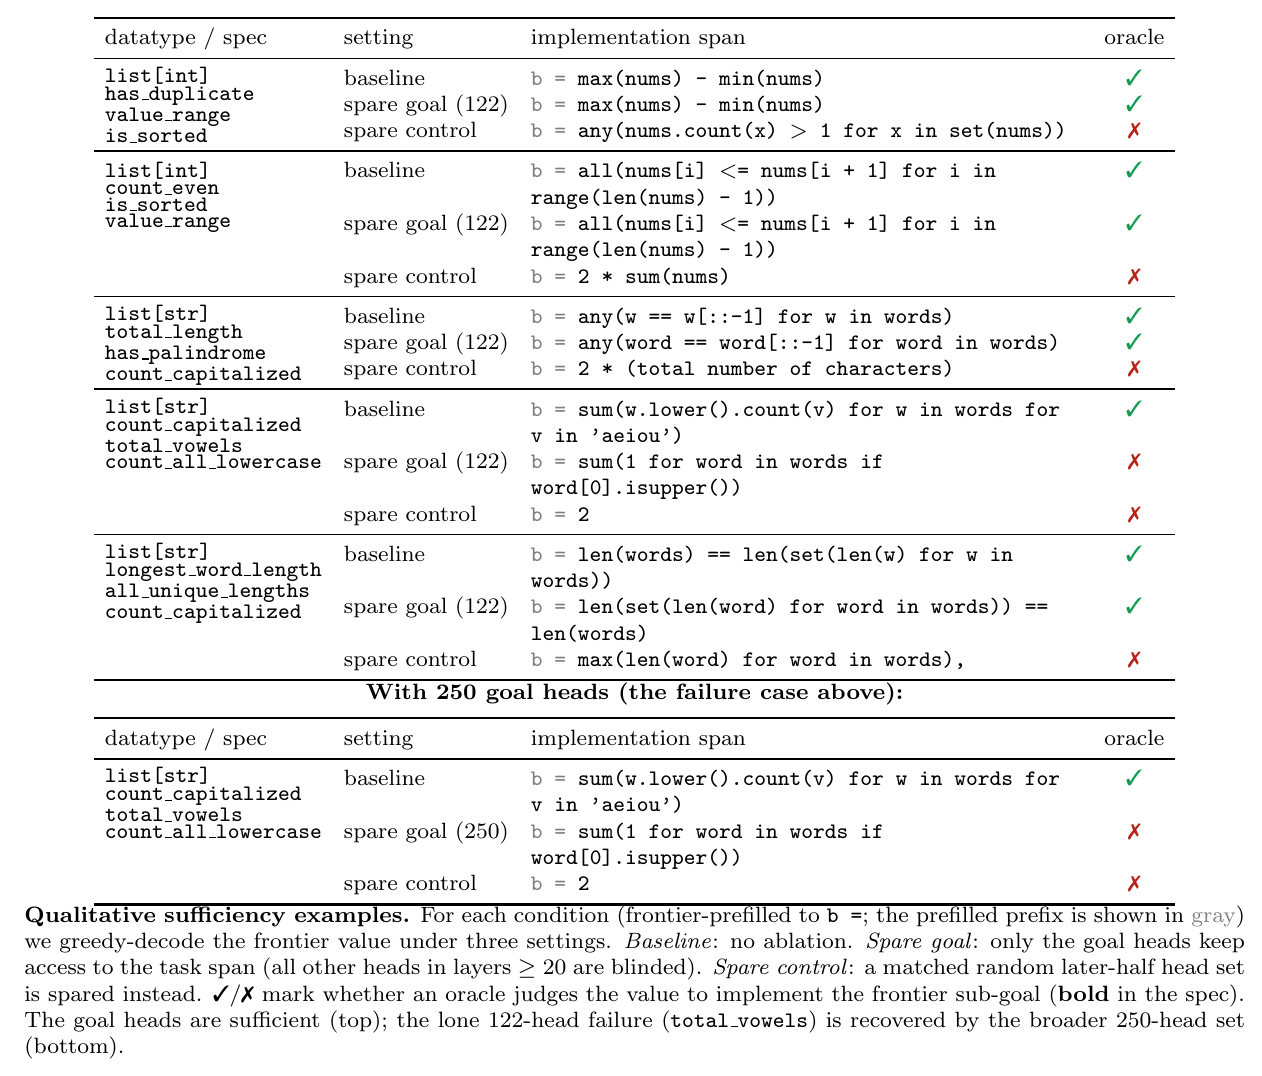

In [11]:
# ── LaTeX table: one float, shared super-caption; main (122) on top, 250-head sub-table below ──
import re, os
sys.path.insert(0, os.path.join(os.getcwd(), "notebooks", "fig_n_table_generators"))
import figstyle as F
from IPython.display import display

SUB250_TARGET = "total_vowels"   # failure example re-shown with 250 heads
# Paste the real 250-head run to replace the placeholder (else = the 122 run for this example):
#   SUB250_OVERRIDE = {"baseline": {"gen": "...", "verdict": "YES"}, "spare_goal": {...}, "spare_control": {...}}
SUB250_OVERRIDE = None
LABEL = "tab:sufficiency-qual"
SUPER_CAPTION = (r"\textbf{Qualitative sufficiency examples.} For each condition (frontier-prefilled to "
    r"\texttt{b =}; the prefilled prefix is shown in \textcolor{gray}{gray}) we greedy-decode the frontier "
    r"value under three settings. \emph{Baseline}: no ablation. \emph{Spare goal}: only the goal heads keep "
    r"access to the task span (all other heads in layers $\geq 20$ are blinded). \emph{Spare control}: a "
    r"matched random later-half head set is spared instead. \ding{51}/\ding{55} mark whether an oracle judges "
    r"the value to implement the frontier sub-goal (\textbf{bold} in the spec). The goal heads are sufficient "
    r"(top); the lone 122-head failure (\texttt{total\_vowels}) is recovered by the broader 250-head set (bottom).")

_TEXMAP = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#", "_": r"\_",
           "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}", "^": r"\textasciicircum{}",
           "<": r"\textless{}", ">": r"\textgreater{}", "|": r"\textbar{}"}
def _texesc(s): return re.sub("|".join(re.escape(k) for k in _TEXMAP), lambda m: _TEXMAP[m.group()], str(s))

def _id_tex(p, target):
    return f"\\textbf{{\\texttt{{{_texesc(p)}}}}}" if p == target else f"\\texttt{{{_texesc(p)}}}"

SPEC_LINE_SKIP = "-2pt"  # huddle datatype + ids tightly together
def _spec_block(datatype, spec_ids, target):
    lines = [f"\\texttt{{{_texesc(datatype)}}}"] + [_id_tex(p, target) for p in spec_ids]
    return "\\shortstack[l]{" + (" \\\\[" + SPEC_LINE_SKIP + "] ").join(lines) + "}"

def _oracle_sym(v):
    return "\\textcolor{ForestGreen}{\\ding{51}}" if str(v).upper().startswith("YES") \
        else "\\textcolor{BrickRed}{\\ding{55}}"

IMPL_W = "7cm"
def _rows(r, budget):
    block = _spec_block(r["datatype"], r["spec_ids"], r["target_pred"])
    var = _texesc(r["var"]); out = []
    for i, (lbl, key) in enumerate([("baseline", "baseline"), (f"spare goal ({budget})", "spare_goal"),
                                    ("spare control", "spare_control")]):
        run = r["runs"][key]
        # gray the prefilled "{var} =" pivot; the generated value stays black
        impl = f"\\texttt{{\\textcolor{{gray}}{{{var} =}} {_texesc(run['gen'])}}}"
        c1 = f"\\multirow{{3}}{{*}}{{{block}}}" if i == 0 else ""
        out.append(f"{c1} & {lbl} & {impl} & {_oracle_sym(run.get('verdict'))} \\\\")
    return "\n".join(out)

def latex_tabular(results, budget):
    body = "\n\\midrule\n".join(_rows(r, budget) for r in results)
    return ("\\begin{tabular}{l l p{" + IMPL_W + "} c}\n\\toprule\n"
            "datatype / spec & setting & implementation span & oracle \\\\\n\\midrule\n"
            + body + "\n\\bottomrule\n\\end{tabular}")

tab_main = latex_tabular(RESULTS, "122")
sub = next((r for r in RESULTS if r["target_pred"] == SUB250_TARGET), None)
sub_used = dict(sub); 
if sub is not None and SUB250_OVERRIDE:
    sub_used["runs"] = SUB250_OVERRIDE
tab_250 = latex_tabular([sub_used], "250") if sub is not None else ""

MID = "{\\centering\\footnotesize\\textbf{With 250 goal heads (the failure case above):}\\par}"
# paper float (shared super-caption)
paper = ("\\begin{table*}[p]\\centering\\footnotesize\\setlength{\\tabcolsep}{4pt}\n"
         + tab_main + "\n\n\\vspace{1em}\n" + MID + "\n\\vspace{0.3em}\n" + tab_250
         + "\n\\caption{" + SUPER_CAPTION + "}\n\\label{" + LABEL + "}\n\\end{table*}")
outdir = os.path.join("notebooks", "Figures", "temporal_persistence"); os.makedirs(outdir, exist_ok=True)
open(os.path.join(outdir, "sufficiency_qual_combined.tex"), "w").write(paper + "\n")
print("# === PAPER TABLE (table*, shared super-caption) ===\n"); print(paper)

# inline preview (standalone can't float a real \caption -> simulate it with a \parbox)
PRE = r"\usepackage{booktabs,array,multirow,pifont}\usepackage[dvipsnames]{xcolor}"
preview = ("\\footnotesize\\setlength{\\tabcolsep}{4pt}\n\\begin{tabular}{@{}c@{}}\n"
           + tab_main + " \\\\[1.2em]\n"
           + "\\textbf{With 250 goal heads (the failure case above):} \\\\[0.4em]\n"
           + tab_250 + " \\\\[1em]\n"
           + "\\parbox{15.5cm}{\\footnotesize " + SUPER_CAPTION + "} \\\\\n\\end{tabular}")
img = F.render_latex_table(preview, preamble=PRE)
display(img) if img is not None else rich_print("[yellow]render failed — .tex saved & printed above[/yellow]")